# システムFでのpostselection付き量子誤り訂正検証

## 目的

Q-DATAの妥当性検証およびQ-DATA上での簡単な実行例を目指し，
$n$量子ビット反復符号を用いた$X$誤り訂正を評価する．

本符号の$X$距離は

$$
d_X=n
$$

であり，最大

$$
t_X=\left\lfloor\frac{d_X-1}{2}\right\rfloor
$$

個の$X$誤りを訂正できる．一方，$Z$誤りは訂正できないため，
本評価は$X$誤りに限定する．

## 例：$d_X=3$の3量子ビット反復符号

論理状態を

$$
\ket{0_L}=\ket{000},
\qquad
\ket{1_L}=\ket{111}
$$

と定義する．

この符号は1個の$X$誤りを訂正できるが，
任意の量子誤りを訂正できる量子符号ではない．
したがって，本検証では$X$誤りのみを対象とする．

### スタビライザと論理基底

論理基底は，

$$
\ket{0_L}=\ket{000},
\qquad
\ket{1_L}=\ket{111}
$$

である．今回は$\ket{0_L}$の準備を考える．

$X$誤りを検出するスタビライザ生成子は，

$$
S_1=Z_1Z_2,
\qquad
S_2=Z_2Z_3
$$

である．対応するパリティ検査行列$H_Z$は，

$$
H_Z=
\begin{pmatrix}
1 & 1 & 0 \\
0 & 1 & 1
\end{pmatrix}
$$

で与えられる．

$X$誤りベクトルを$\mathbf{e}_X$とすると，
シンドロームは二進表現で

$$
\mathbf{s}
=
H_Z\mathbf{e}_X
\pmod 2
$$

となる．

### 状態準備回路
今回はリセットのみで$\ket{0_L}$を作ることができる．したがって，以下のような量子回路で与えられる．

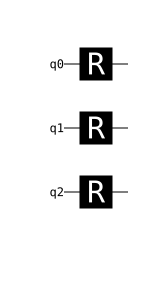

In [ ]:
import numpy as np
import stim
from IPython.display import display

def generate_data_qubits(d=3):
    bpf_circuit = stim.Circuit()
    bpf_circuit.append("R", list(range(d)))
    return bpf_circuit
display(generate_data_qubits().diagram("timeline-svg"))

# 直接測定による量子誤り訂正
直接測定により，この符号を
これは，古典誤り訂正と原理は同じであり，$|000>$を直接測定し，$|000>$か$|111>$かどうかを判別する．

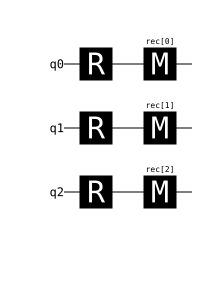

In [ ]:
def x_measurement(d:int=3,circuit:stim.Circuit|None=None) -> stim.Circuit:
    if circuit is None:
        circuit = stim.Circuit()
    circuit.append("M", list(range(d)))
    return circuit
zero_state_circuit = generate_data_qubits()
bpf_direct_circuit = x_measurement(circuit=zero_state_circuit)
display(bpf_direct_circuit.diagram("timeline-svg"))

#　ノイズの追加
circuit_level_noiseを追加する．

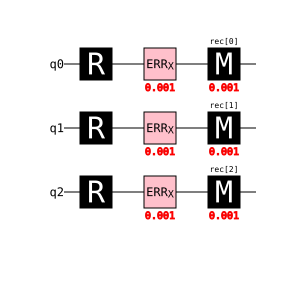

In [ ]:
from circuit_level_noise import add_noise
bpf_direct_circuit_w_noise = add_noise(bpf_direct_circuit,p=0.001)
display(bpf_direct_circuit_w_noise.diagram("timeline-svg"))

# コード容量閾値の計測
測定が理想である時，閾値は1/2となる．

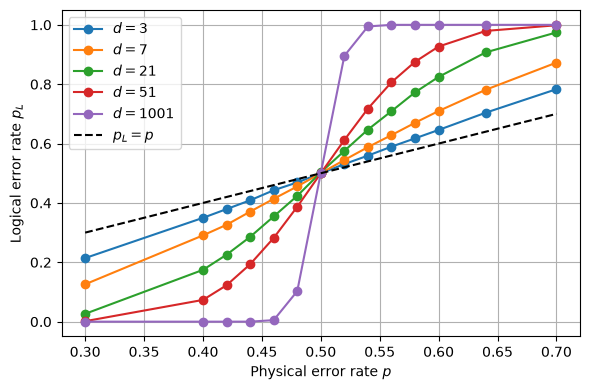

In [ ]:
import matplotlib.pyplot as plt

ps = [0.3, 0.4, 0.42,0.44,0.46, 0.48, 0.5, 0.52,0.54, 0.56,0.58, 0.6, 0.64, 0.7]
distances = [3, 7,21, 51, 1001]
shots = 100_000

fig, ax = plt.subplots(figsize=(6, 4))

for d in distances:
    circuit = x_measurement(d=d, circuit=generate_data_qubits(d=d))
    ler:list[float] = []

    for p in ps:
        noisy_circuit = add_noise(circuit, p=p, p_meas=0)

        samples = (
            noisy_circuit
            .compile_sampler()
            .sample(shots=shots)
        )

        # 各ショットについて、1が過半数なら論理エラー
        logical_errors = samples.sum(axis=1) > d // 2
        ler.append(logical_errors.mean())

    ax.plot(
        ps,
        ler,
        "o-",
        label=f"$d={d}$",
    )

ax.plot(
    ps,
    ps,
    "k--",
    label=r"$p_L=p$",
)

ax.set(
    xlabel=r"Physical error rate $p$",
    ylabel=r"Logical error rate $p_L$",
    #xscale="log",
    #yscale="log",
)

ax.grid(which="both")
ax.legend()

plt.tight_layout()
plt.show()

# シンドローム間接測定

## 直接測定の課題
上記のような直接測定による誤り訂正は，データを破壊する．任意の符号化された量子状態$\alpha \ket{000}+\beta{111}$のビット反転誤り訂正符号を直接測定すると，
$$
\begin{cases}
    \ket{000}\qquad (\text{確率}|\alpha|^2)\\
    \ket{111}\qquad (\text{確率}|\beta|^2)
\end{cases}
$$
従って，直接測定は使用できない．

# 単一のシンドローム測定
シンドローム測定により，誤りがあるかどうかを判定する．
+1なら誤り無し，-1なら誤りあり．

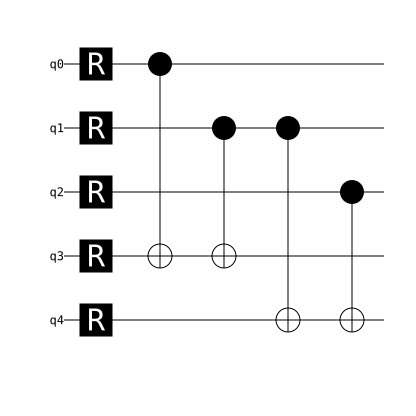

In [ ]:
def generate_data_plus_one_round_syndrome_ancilla():
    bpf_circuit = generate_data_qubits()
    bpf_circuit.append("R",[3,4]) # syndrome measurement用 ancillaの準備
    bpf_circuit.append("CX",[0,3])
    bpf_circuit.append("CX",[1,3])
    bpf_circuit.append("CX",[1,4])
    bpf_circuit.append("CX",[2,4])
    return bpf_circuit

display(generate_data_plus_one_round_syndrome_ancilla().diagram("timeline-svg"))

# 2-round syndrome測定による誤り訂正

最も簡単なプロトコルとして，2 roundのシンドローム測定を用いた
$X$誤り訂正を行う．

時刻1および時刻2で得られたシンドロームを，それぞれ
$\mathbf{s}^{(1)}$，$\mathbf{s}^{(2)}$ とする．
シンドローム測定自体に誤りが生じる可能性を考慮し，

$$
\mathbf{s}^{(1)}=\mathbf{s}^{(2)}
$$

を満たすshotのみをacceptし，不一致のshotをrejectする．
acceptされたshotについては，共通のシンドロームを用いて復号する．

最後にデータ量子ビットを直接$Z$測定し，復号後の論理値から
条件付き論理誤り率

$$
P_L\mid\mathrm{accept}
=
\frac{
N_{\mathrm{logical\ failure}\cap\mathrm{accept}}
}{
N_{\mathrm{accept}}
}
$$

を評価する．また，postselectionに伴うオーバーヘッドを評価するため，
acceptance rate

$$
P_{\mathrm{accept}}
=
\frac{N_{\mathrm{accept}}}{N_{\mathrm{total}}}
$$

も併記する．

両roundで同じ非自明シンドロームが得られた場合は，必ずしも
false acceptではない．これは，round 1以前に発生したデータ誤りを
両roundで正しく検出した可能性があるためである．

false acceptとは，shotがacceptされたにもかかわらず，
復号後に論理誤りが残る事象を指す．

距離$d_X$の符号が

$$
t=\left\lfloor\frac{d_X-1}{2}\right\rfloor
$$

個の$X$誤りを訂正でき，誤り訂正回路がfault-tolerantである場合，
低物理誤り率領域では

$$
P_L
=
O\left(p^{t+1}\right)
=
O\left(
p^{\left\lfloor(d_X-1)/2\right\rfloor+1}
\right)
$$

のスケーリングが期待される．

ただし，2 roundのシンドローム一致だけでは，このスケーリングは
保証されない．実際のスケーリングは，シンドローム測定回路を含む
ノイズシミュレーションまたは実験結果から確認する．

In [ ]:
import stim


def generate_data_plus_two_round_syndrome_ancilla():
    circuit = generate_data_qubits()

    # ========================================
    # Round 1: ancilla 3, 4
    # ========================================
    circuit.append("R", [3, 4])
    circuit.append("TICK")

    circuit.append("CX", [0, 3])
    circuit.append("CX", [1, 3])

    circuit.append("CX", [1, 4])
    circuit.append("CX", [2, 4])

    circuit.append("M", [3, 4])
    circuit.append("TICK")

    # 初期状態 |000> の期待シンドロームは 00
    #
    # 現時点では
    # rec[-2] = round 1: Z0 Z1
    # rec[-1] = round 1: Z1 Z2
    circuit.append(
        "DETECTOR",
        [stim.target_rec(-2)],
    )
    circuit.append(
        "DETECTOR",
        [stim.target_rec(-1)],
    )

    # ========================================
    # Round 2: ancilla 5, 6
    # ========================================
    circuit.append("R", [5, 6])
    circuit.append("TICK")

    circuit.append("CX", [0, 5])
    circuit.append("CX", [1, 5])

    circuit.append("CX", [1, 6])
    circuit.append("CX", [2, 6])

    circuit.append("M", [5, 6])
    circuit.append("TICK")

    # ========================================
    # Round 1 と Round 2 の比較
    #
    # rec[-4] = round 1: Z0 Z1
    # rec[-3] = round 1: Z1 Z2
    # rec[-2] = round 2: Z0 Z1
    # rec[-1] = round 2: Z1 Z2
    # ========================================
    circuit.append(
        "DETECTOR",
        [
            stim.target_rec(-4),
            stim.target_rec(-2),
        ],
    )
    circuit.append(
        "DETECTOR",
        [
            stim.target_rec(-3),
            stim.target_rec(-1),
        ],
    )

    # ========================================
    # Final direct Z measurement of data
    # ========================================
    circuit.append("M", [0, 1, 2])

    # 現時点の測定記録:
    #
    # rec[-7] = round 1: Z0 Z1
    # rec[-6] = round 1: Z1 Z2
    # rec[-5] = round 2: Z0 Z1
    # rec[-4] = round 2: Z1 Z2
    # rec[-3] = data 0
    # rec[-2] = data 1
    # rec[-1] = data 2

    # Round 2と最終データパリティの比較
    circuit.append(
        "DETECTOR",
        [
            stim.target_rec(-5),
            stim.target_rec(-3),
            stim.target_rec(-2),
        ],
    )
    circuit.append(
        "DETECTOR",
        [
            stim.target_rec(-4),
            stim.target_rec(-2),
            stim.target_rec(-1),
        ],
    )

    # |000> / |111>を区別する論理Z測定
    # 符号空間内では任意のデータ測定1個でよい
    circuit.append(
        "OBSERVABLE_INCLUDE",
        [stim.target_rec(-3)],
        0,
    )

    return circuit

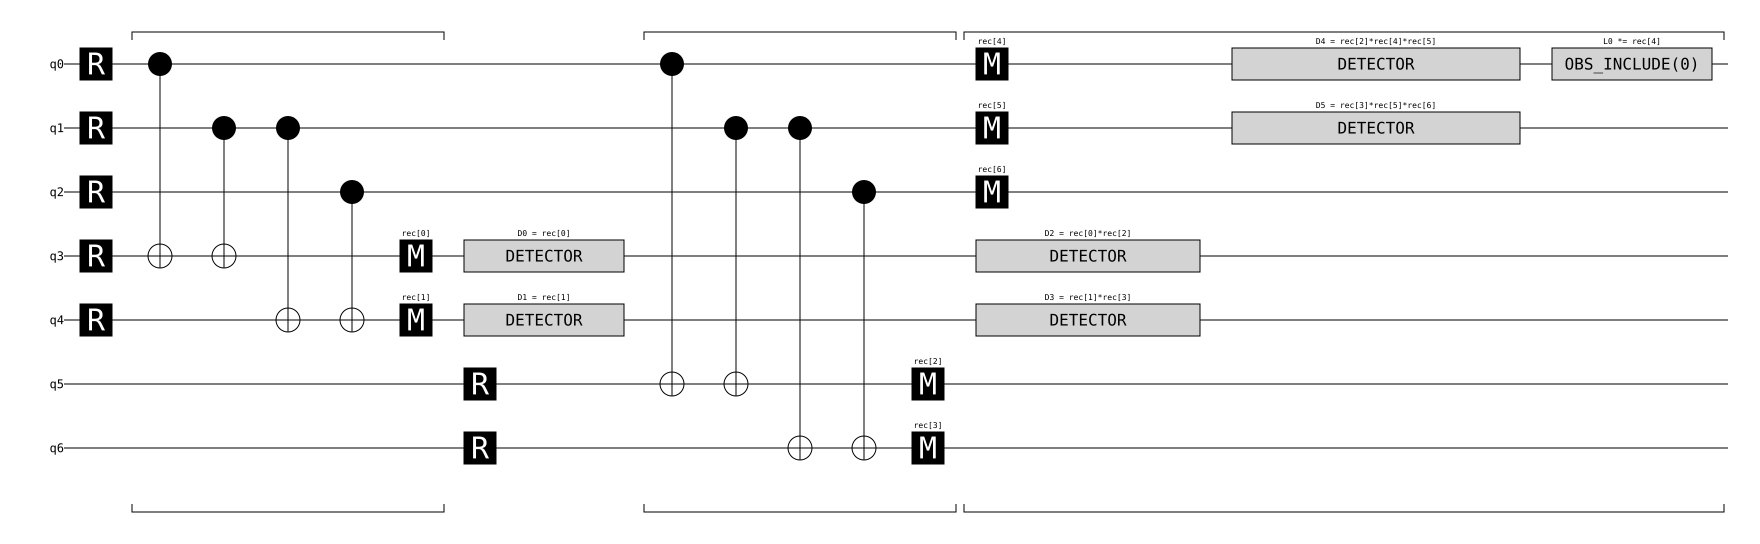

In [ ]:
bpf_circuit = generate_data_plus_two_round_syndrome_ancilla()
display(bpf_circuit.diagram("timeline-svg"))

## 訂正手順

1. データ量子ビットを初期化し，
   $\ket{0_L}=\ket{000}$を準備する．
2. 2個のancillaを用いて，round 1のシンドローム
   $\mathbf{s}^{(1)}$を測定する．
3. 別の2個のancillaを用いて，round 2のシンドローム
   $\mathbf{s}^{(2)}$を測定する．
4. データ量子ビットを$Z$基底で直接測定する．
5. $\mathbf{s}^{(1)}=\mathbf{s}^{(2)}$を満たすshotのみを
   acceptし，不一致のshotをrejectする．
6. acceptされたshotについて，共通のシンドロームに基づいて
   データ測定結果を古典的に補正する．
7. 補正後のデータ測定結果をmajority voteで復号し，
   論理値が$0$であるかを判定する．

### 評価条件

- 準備状態：$\ket{0_L}=\ket{000}$
- 雑音モデル：$X$雑音
- 評価量：
  - acceptance rate $P(\mathrm{accept})$
  - 条件付き論理誤り率
    $\mathrm{LER}\mid\mathrm{accept}$

## Stimによる数値シミュレーション

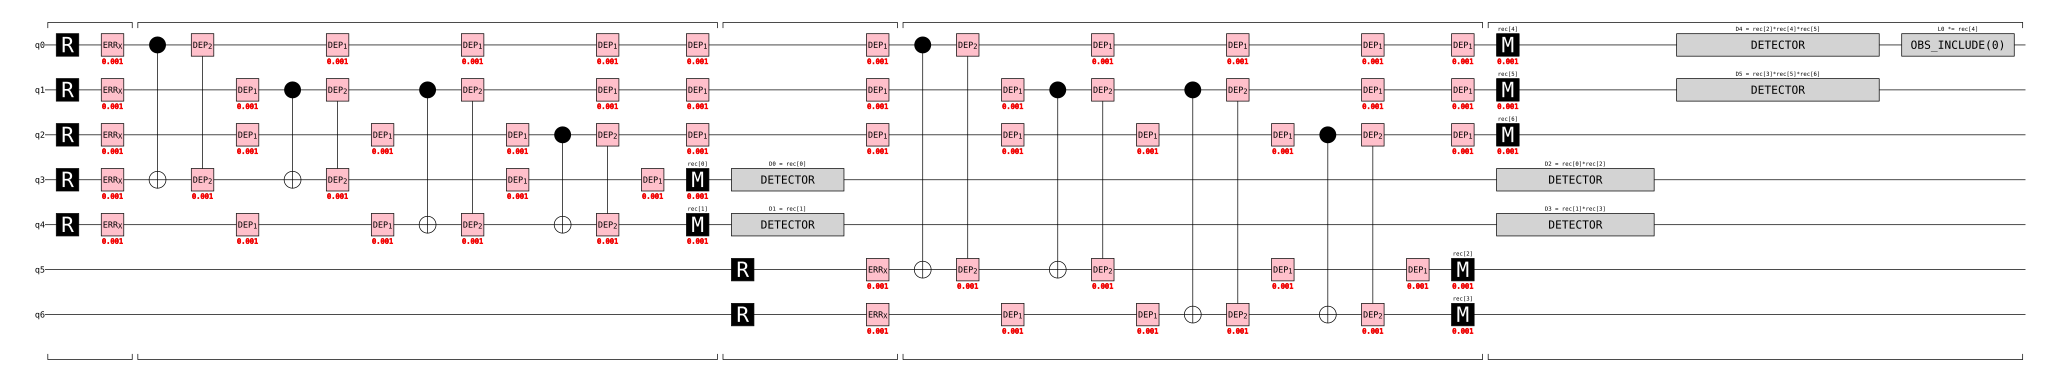

acceptance rate: 0.9589
accepted shots: 9589


In [ ]:
from circuit_level_noise import add_noise

bpf_circuit_w_noise = add_noise(bpf_circuit,p=0.001)
display(bpf_circuit_w_noise.diagram("timeline-svg"))

sampler = bpf_circuit_w_noise.compile_detector_sampler()

detectors = sampler.sample(shots=10_000)

accepted = ~np.any(detectors, axis=1)

print("acceptance rate:", accepted.mean())
print("accepted shots:", accepted.sum())

In [ ]:
import pymatching

def evaluate(
    circuit:stim.Circuit,
    distance:int,
    shots:int=100_000,
    detection_mode:bool=False,
    rounds:int=2,
) -> tuple[float, float]:
    n_checks = distance - 1

    if detection_mode:
        samples = circuit.compile_sampler().sample(shots=shots)

        expected_bits = rounds * n_checks + distance

        if samples.shape[1] != expected_bits:
            raise ValueError(
                f"Expected {expected_bits} measurement bits, "
                f"but got {samples.shape[1]}."
            )

        syndromes = samples[
            :, :rounds * n_checks
        ].reshape(
            samples.shape[0],
            rounds,
            n_checks,
        )

        data = samples[:, -distance:]

        # 全ラウンドのシンドロームが一致するshotだけ採用
        accept = np.all(
            syndromes == syndromes[:, :1, :],
            axis=(1, 2),
        )

        if not np.any(accept):
            return 0.0, np.nan

        logical_error = (
            data[accept].sum(axis=1) > distance // 2
        )

        return accept.mean(), logical_error.mean()

    # MWPMによる訂正
    detection_events, actual_observables = (
        circuit.compile_detector_sampler().sample(
            shots=shots,
            separate_observables=True,
        )
    )

    if actual_observables.shape[1] != 1:
        raise ValueError(
            "Exactly one logical observable is required. "
            f"Found {actual_observables.shape[1]}."
        )

    detector_error_model = circuit.detector_error_model(decompose_errors=True)

    matching = pymatching.Matching.from_detector_error_model(detector_error_model)

    predicted_observables = matching.decode_batch(detection_events)

    logical_error = (predicted_observables[:, 0]!= actual_observables[:, 0])

    return 1.0, logical_error.mean()

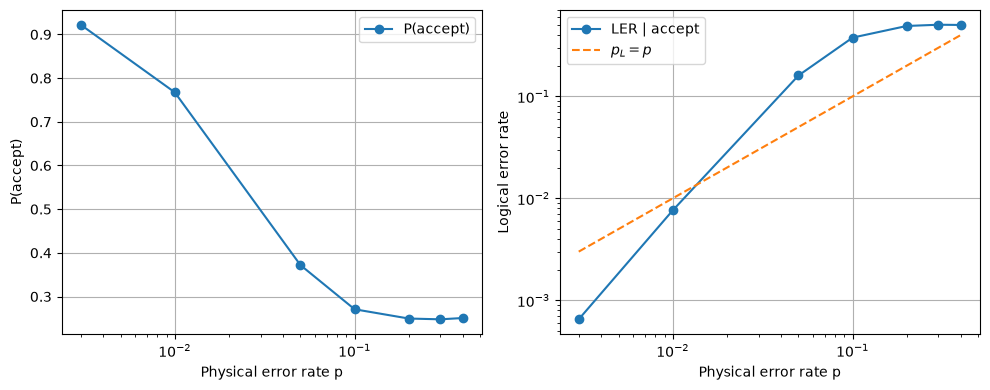

In [ ]:
import matplotlib.pyplot as plt

ps = [0.003, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4]
p_accepts, ler_accepts = [], []

for p in ps:
    noisy_circuit = add_noise(bpf_circuit, p=p)
    p_accept, ler_accept = evaluate(noisy_circuit,distance=3,detection_mode=True)

    p_accepts.append(p_accept)
    ler_accepts.append(ler_accept)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(ps, p_accepts, "o-", label="P(accept)")
axes[0].set(xlabel="Physical error rate p", ylabel="P(accept)", xscale="log")
axes[0].grid()
axes[0].legend()

axes[1].plot(ps, ler_accepts, "o-", label="LER | accept")
axes[1].plot(ps, ps, "--", label=r"$p_L=p$")
axes[1].set(
    xlabel="Physical error rate p",
    ylabel="Logical error rate",
    xscale="log",
    yscale="log",
)
axes[1].grid()
axes[1].legend()

plt.tight_layout()
plt.show()

# より大きな符号の評価

In [ ]:
import stim


def generate_circuit(distance, rounds=None):
    if distance < 3 or distance % 2 == 0:
        raise ValueError(
            "distance must be an odd integer >= 3"
        )

    if rounds is None:
        rounds = distance

    circuit = stim.Circuit()

    # データ量子ビットを |00...0> に初期化
    circuit.append("R", list(range(distance)))
    circuit.append("TICK")

    n_checks = distance - 1

    for r in range(rounds):
        ancillas = list(
            range(
                distance + r * n_checks,
                distance + (r + 1) * n_checks,
            )
        )

        # ancillaを初期化
        circuit.append("R", ancillas)
        circuit.append("TICK")

        # Zi Zi+1 のパリティ測定
        for i, ancilla in enumerate(ancillas):
            circuit.append(
                "CX",
                [
                    i,
                    ancilla,
                    i + 1,
                    ancilla,
                ],
            )

        circuit.append("M", ancillas)
        circuit.append("TICK")

        if r == 0:
            # 初期状態 |00...0> のシンドロームはすべて0
            for i in range(n_checks):
                circuit.append(
                    "DETECTOR",
                    [
                        stim.target_rec(
                            -n_checks + i
                        )
                    ],
                )
        else:
            # 前ラウンドと現在ラウンドの比較
            for i in range(n_checks):
                circuit.append(
                    "DETECTOR",
                    [
                        stim.target_rec(
                            -2 * n_checks + i
                        ),
                        stim.target_rec(
                            -n_checks + i
                        ),
                    ],
                )

    # 最終データ測定
    circuit.append("M", list(range(distance)))

    # 測定記録の末尾:
    # [最終ラウンドのsyndrome: distance-1個]
    # [最終data測定: distance個]

    # 最終syndromeとデータパリティの比較
    for i in range(n_checks):
        circuit.append(
            "DETECTOR",
            [
                # 最終syndrome i
                stim.target_rec(
                    -(distance + n_checks - i)
                ),

                # data i
                stim.target_rec(
                    -(distance - i)
                ),

                # data i+1
                stim.target_rec(
                    -(distance - i - 1)
                ),
            ],
        )

    # logical Z
    # 最終データ測定の左端ビット
    circuit.append(
        "OBSERVABLE_INCLUDE",
        [
            stim.target_rec(-distance)
        ],
        0,
    )

    # これが欠けるとNoneになる
    return circuit

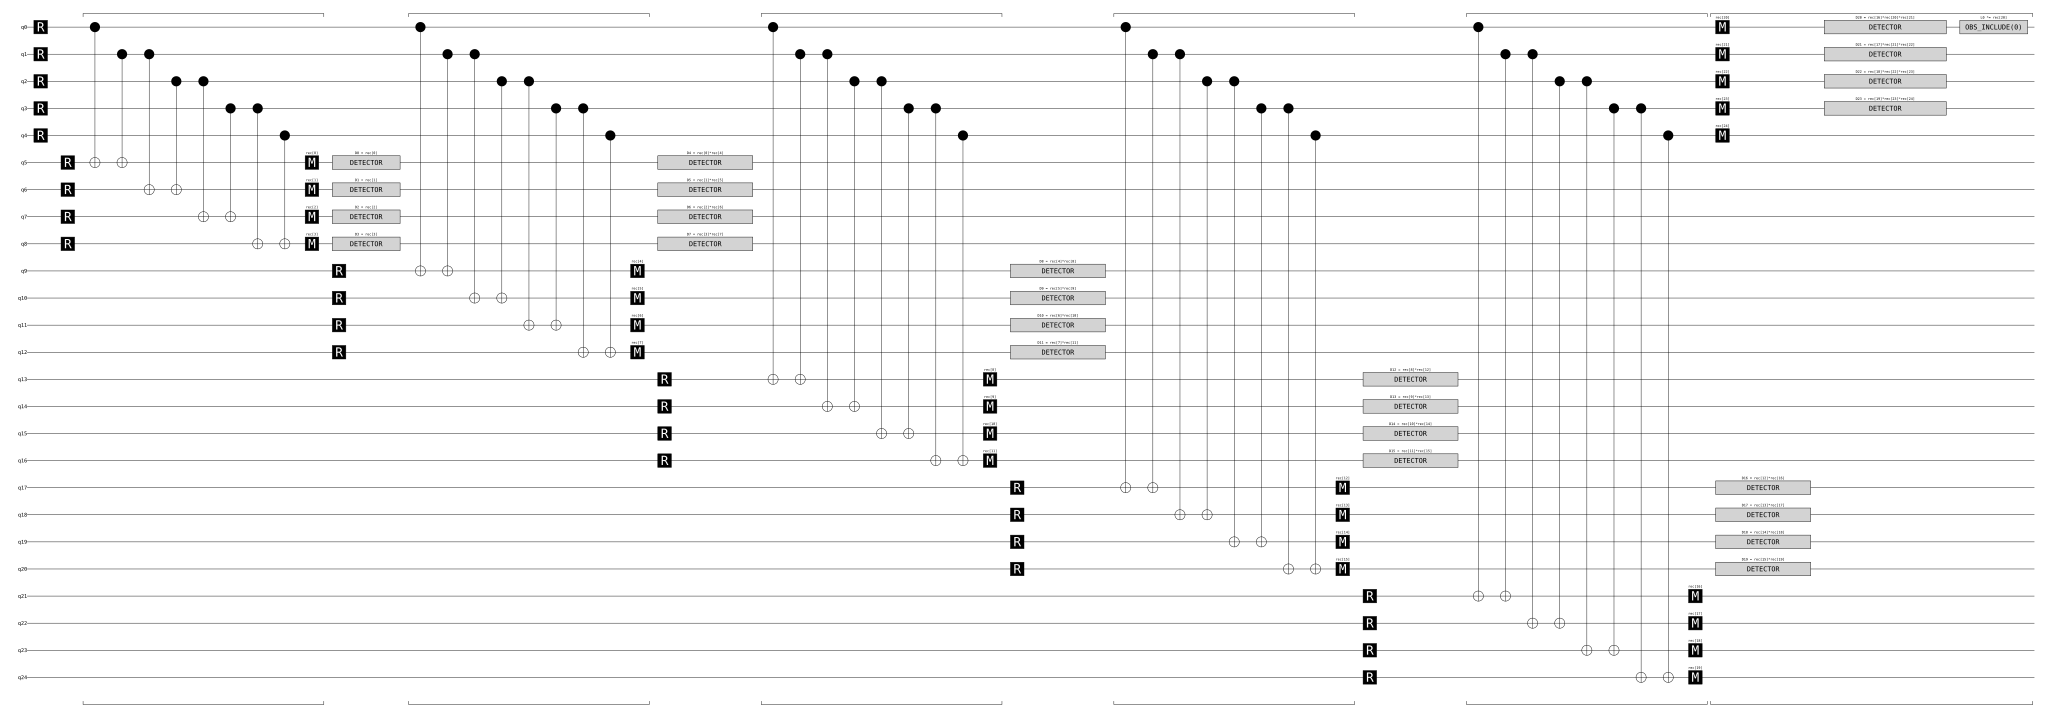

In [ ]:
display(generate_circuit(5).diagram("timeline-svg"))

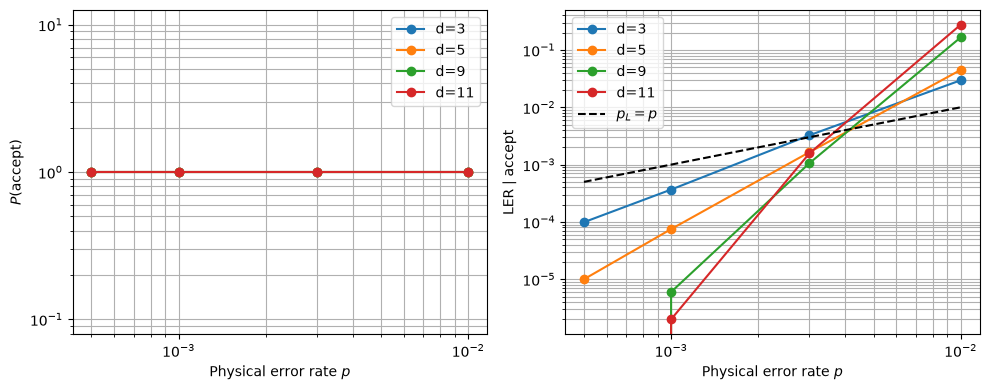

In [ ]:
import matplotlib.pyplot as plt

ps = [0.001, 0.003, 0.01]
distances = [3, 5, 9, 11]
shots = 1_000_000

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for d in distances:
    circuit = generate_circuit(d)
    p_accepts = []
    ler_accepts = []

    for p in ps:
        noisy_circuit = add_noise(circuit, p=p)
        p_accept, ler_accept = evaluate(
            noisy_circuit,
            distance=d,
            shots=shots,
        )

        p_accepts.append(p_accept)
        ler_accepts.append(ler_accept)

    axes[0].plot(
        ps,
        p_accepts,
        "o-",
        label=f"d={d}",
    )
    axes[1].plot(
        ps,
        ler_accepts,
        "o-",
        label=f"d={d}",
    )

axes[0].set(
    xlabel="Physical error rate $p$",
    ylabel="$P(\\mathrm{accept})$",
    xscale="log",
    yscale="log",
)
axes[0].grid(which="both")
axes[0].legend()

axes[1].plot(
    ps,
    ps,
    "k--",
    label=r"$p_L=p$",
)
axes[1].set(
    xlabel="Physical error rate $p$",
    ylabel=r"$\mathrm{LER}\mid\mathrm{accept}$",
    xscale="log",
    yscale="log",
)
axes[1].grid(which="both")
axes[1].legend()

plt.tight_layout()
plt.show()

# 実機での評価イメージ

物理誤り率がほぼ固定された実機環境において，符号距離$d_X$を変更し，
postselection後の条件付き論理誤り率を評価する．

- 横軸：$X$距離$d_X$
- 縦軸：条件付き論理誤り率
  $\mathrm{LER}\mid\mathrm{accept}$

各距離について，$P_{\mathrm{accept}}=\frac{N_{\mathrm{accept}}}{N_{\mathrm{total}}}$と$\mathrm{LER}$を取得する．

符号距離$d_X$の増加に伴い，
$\mathrm{LER}\mid\mathrm{accept}$が低下するかを確認する．

ただし，距離の増加に伴ってデータ量子ビット数，ancilla数，
2量子ビットゲート数および回路深さも増加するため，
実機では論理誤り率が必ずしも単調に低下するとは限らない．

したがって，$\mathrm{LER}\mid\mathrm{accept}$だけでなく，
$P_{\mathrm{accept}}$およびacceptされたshot数も併記する．

In [ ]:
import matplotlib.pyplot as plt

p = 1e-3
distances = [3, 5, 7, 9, 13]
shots = 1_000_000

lers = []
p_accepts = []

for d in distances:
    circuit = generate_circuit(d)
    noisy_circuit = add_noise(circuit, p=p)

    p_accept, ler_accept = evaluate(
        noisy_circuit,
        distance=d,
        shots=shots,
    )

    p_accepts.append(p_accept)
    lers.append(ler_accept)

plt.plot(distances, lers, "o-", label=r"$\mathrm{LER}\mid\mathrm{accept}$")
plt.axhline(p, color="black", linestyle="--", label=r"$p_L=p=5\times10^{-3}$")

plt.xlabel("Code distance $d$")
plt.ylabel("Logical error rate")
plt.yscale("log")
plt.xticks(distances)
plt.grid(which="both")
plt.legend()
plt.tight_layout()
plt.show()